Les packages

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

Dans la suite du notebook on défini les paramètres suivants : 

* $S_0$ : le prix initial du sous-jacent,
* $K$ : le prix d'exercice (strike),
* $\sigma$ : la volatilité,
* $r$ : le taux d'intérêt sans risque,
* $q$ : le taux de dividende continu,
* $T$ : la maturité de l'option (en années),
* $N$ : le nombre de pas de temps.

Création d'une fonction qui représente l'evolution du prix du sous jacent en fonction du temps, a l'aide du mouvement brownien

In [49]:
def generer_traj(S0, sigma, r, q, T, N): 
    dt = T/N
    S = np.zeros(N+1)
    S[0] = S0
    for i in range(1, N+1):
        epsilon = np.random.randn()
        dz = epsilon * np.sqrt(dt)
        dG = (r - q - (sigma**2)/2)*dt + sigma*dz 
        S[i] = S[i-1] * np.exp(dG)
    return S

Graphique du cours d'un sous-jacent en fonction du temps avec le mouvement brownien

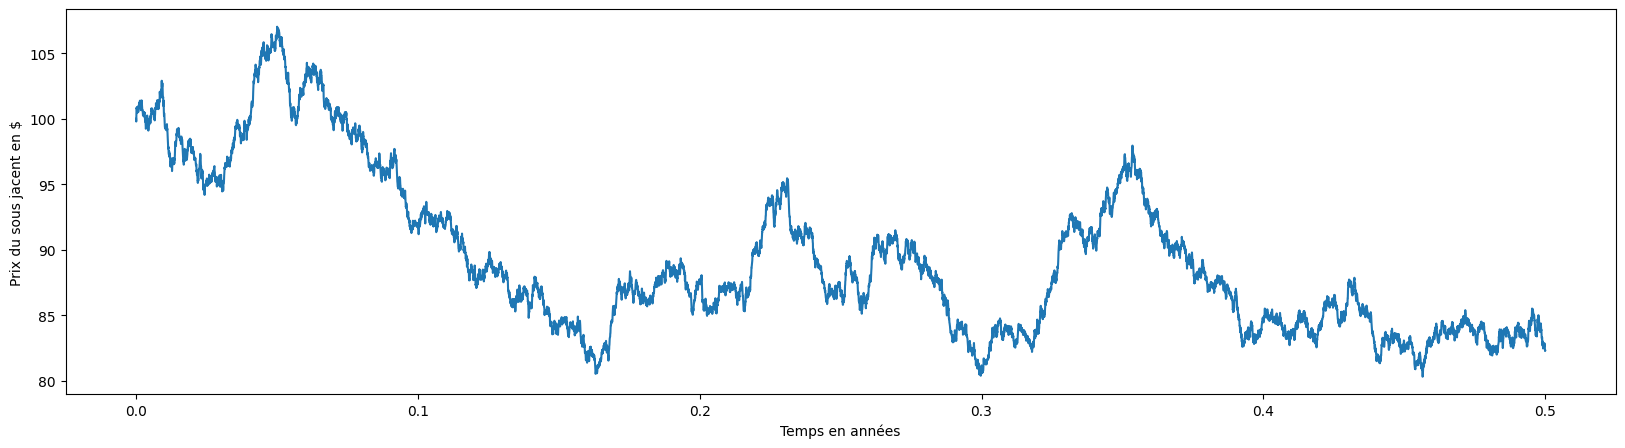

In [50]:
S0 = 100
sigma = 0.30
r = 0.15
q = 0.02
T = 0.5
N = 10000

prix = generer_traj(S0, sigma, r, q, T, N)
t = np.linspace(0, T, len(prix))

plt.figure(figsize=(20, 5))

plt.plot(t, prix)
plt.xlabel("Temps en années")
plt.ylabel("Prix du sous jacent en $")
plt.show()


## Le $\Delta$

In [51]:
def Delta_t(S, K, sigma, r, q, T, N, option_type):
    dt = T / N
    Delta = np.zeros(N + 1)
        
    for i in range(N + 1):
        tau = T - i * dt
        
        # Gestion du cas à l'échéance (tau = 0) pour éviter la division par zéro
        if tau <= 1e-10:
            if option_type == 'call':
                Delta[i] = 1.0 if S[i] > K else 0.0
            elif option_type == 'put':
                Delta[i] = 0.0 if S[i] > K else -1.0
            continue 
            
        # Calcul de d1 
        d1 = (np.log(S[i] / K) + (r - q + (sigma**2) / 2) * tau) / (sigma * np.sqrt(tau))
        
        # Calcul du Delta selon le type d'option
        if option_type == 'call':
            Delta[i] = np.exp(-q * tau) * norm.cdf(d1)
        elif option_type == 'put':
            Delta[i] = np.exp(-q * tau) * (norm.cdf(d1) - 1)
            
    return Delta

Graphique du $\Delta$ en fonction du temps

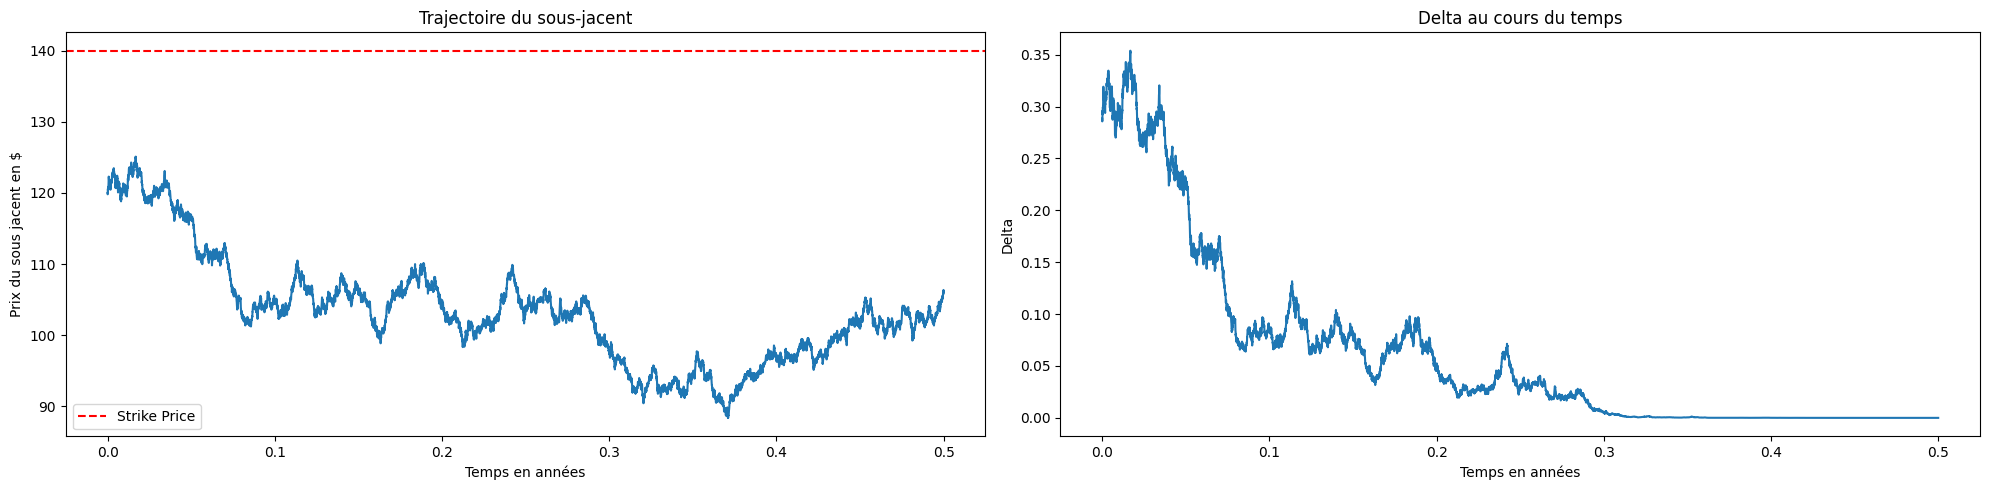

In [61]:
#Paramètres
S0 = 120
sigma = 0.3
r = 0.05
K = 140
T = 0.5
N = 10000
q = 0.02
option_type = 'call'

S = generer_traj(S0, sigma, r, q, T, N)
delta = Delta_t(S, K, sigma, r, q, T, N, option_type)
t1 = np.linspace(0, T, len(delta))
t2 = np.linspace(0, T, len(S))

plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1)
plt.plot(t2, S)
plt.axhline(y=K, color='r', linestyle='--', label='Strike Price')
plt.xlabel("Temps en années")
plt.ylabel("Prix du sous jacent en $")
plt.title("Trajectoire du sous-jacent")
plt.legend(loc='best')

plt.subplot(1, 2, 2)
plt.plot(t1, delta)
plt.xlabel("Temps en années")
plt.ylabel("Delta")
plt.title("Delta au cours du temps")

plt.tight_layout()
plt.show()

## Le $\Gamma$

In [53]:
def Gamma_t(S, K, sigma, r, q, T, N, option_type):
    dt = T / N
    gamma = np.zeros(N + 1)
        
    for i in range(N + 1):
        tau = T - i * dt
        
        if tau <= 1e-10:
            gamma[i] = 0.0 
            continue
            
        # Calcul de d1 
        d1 = (np.log(S[i] / K) + (r - q + (sigma**2) / 2) * tau) / (sigma * np.sqrt(tau))
        
        # Calcul du Gamma pour les deux types d'options (le Gamma est le même pour les calls et les puts)
        gamma[i] = (np.exp(-q * tau) * norm.pdf(d1)) / (S[i] * sigma * np.sqrt(tau))
        
    return gamma

Comparaison entre la varition du Gamma, du Delta et du prix du sous jacent en fonction du temps

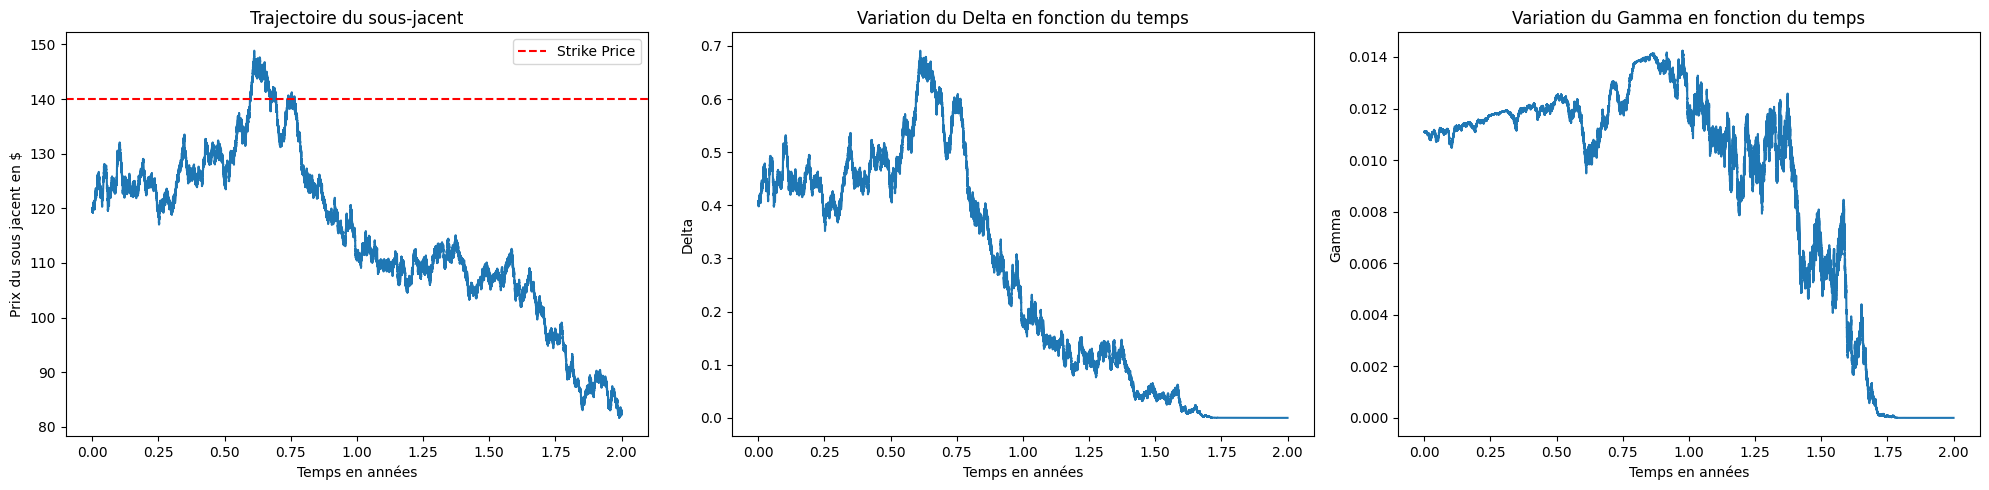

In [54]:
#Paramètres
S0 = 120
sigma = 0.2
r = 0.05
q = 0.02
K = 140
T = 2
N = 100000
option_type = 'call'


S = generer_traj(S0, sigma, r, q, T, N)
gamma = Gamma_t(S, K, sigma, r, q, T, N, option_type)
delta = Delta_t(S, K, sigma, r, q, T, N, option_type)
t1 = np.linspace(0, T, len(gamma))
t2 = np.linspace(0, T, len(S))
t3 = np.linspace(0, T, len(delta))

plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
plt.plot(t2, S)
plt.axhline(y=K, color='r', linestyle='--', label='Strike Price')
plt.xlabel("Temps en années")   
plt.ylabel("Prix du sous jacent en $")  
plt.title("Trajectoire du sous-jacent") 
plt.legend(loc='best')

plt.subplot(1, 3, 2)
plt.plot(t3, delta)
plt.xlabel("Temps en années")
plt.ylabel("Delta")
plt.title("Variation du Delta en fonction du temps")

plt.subplot(1, 3, 3)
plt.plot(t1, gamma)
plt.xlabel("Temps en années")
plt.ylabel("Gamma")
plt.title("Variation du Gamma en fonction du temps")

plt.tight_layout()    
plt.show()  

## Le $\Theta$

In [55]:
def Theta_t(S, K, sigma, r, q, T, N, option_type='call'):
    dt = T / N
    theta = np.zeros(N + 1)
    
    for i in range(N + 1):
        tau = T - i * dt
        
        if tau <= 1e-10:
            theta[i] = 0.0
            continue
            
        # Calcul de d1 et d2
        d1 = (np.log(S[i] / K) + (r - q + (sigma**2) / 2) * tau) / (sigma * np.sqrt(tau))
        d2 = d1 - sigma * np.sqrt(tau)
        
        # Ce premier terme est exactement le même pour le Call et le Put
        terme_commun = -(S[i] * np.exp(-q * tau) * norm.pdf(d1) * sigma) / (2 * np.sqrt(tau))
        
        # Calcul du Theta selon le type d'option
        if option_type == 'call':
            theta[i] = terme_commun + q * S[i] * np.exp(-q * tau) * norm.cdf(d1) - r * K * np.exp(-r * tau) * norm.cdf(d2)
        elif option_type == 'put':
            # Notez l'utilisation de -d1 et -d2 dans les norm.cdf pour le Put
            theta[i] = terme_commun - q * S[i] * np.exp(-q * tau) * norm.cdf(-d1) + r * K * np.exp(-r * tau) * norm.cdf(-d2)
            
    return theta

Evolution du $\Theta$ en fonction du temps.

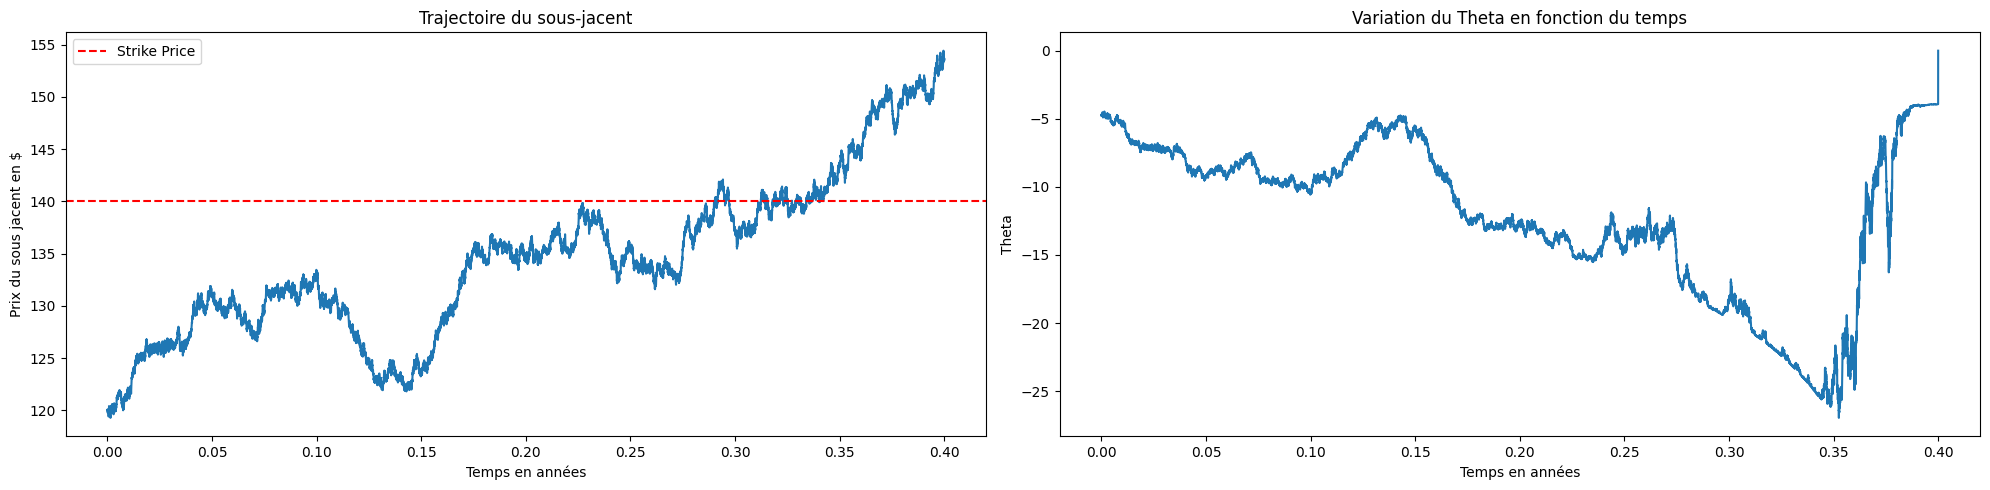

In [56]:
#Paramètres
S0 = 120
sigma = 0.2
r = 0.05
q = 0.02
K = 140
T = 0.4
N = 25000
option_type = 'call'

S = generer_traj(S0, sigma, r, q, T, N)
theta = Theta_t(S, K, sigma, r, q, T, N, option_type)
t1 = np.linspace(0, T, len(theta))
t2 = np.linspace(0, T, len(S))


plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1)
plt.plot(t2, S)
plt.axhline(y=K, color='r', linestyle='--', label='Strike Price')
plt.xlabel("Temps en années")   
plt.ylabel("Prix du sous jacent en $")  
plt.title("Trajectoire du sous-jacent") 
plt.legend(loc='best')

plt.subplot(1, 2, 2)
plt.plot(t1, theta)
plt.xlabel("Temps en années")
plt.ylabel("Theta")
plt.title("Variation du Theta en fonction du temps")

plt.tight_layout()    
plt.show()  

## Le $\nu$

In [57]:
def Vega_t(S, K, sigma, r, q, T, N, option_type='call'):
    dt = T / N
    vega = np.zeros(N + 1)
    
    for i in range(N + 1):
        tau = T - i * dt
        
        if tau <= 1e-10:
            vega[i] = 0.0
            continue
            
        # Calcul de d1 
        d1 = (np.log(S[i] / K) + (r - q + (sigma**2) / 2) * tau) / (sigma * np.sqrt(tau))
        
        # Calcul du Vega (identique pour Call et Put)
        vega[i] = S[i] * np.exp(-q * tau) * np.sqrt(tau) * norm.pdf(d1)
        
    return vega

Evolution du $\nu$ en fonction du temps.

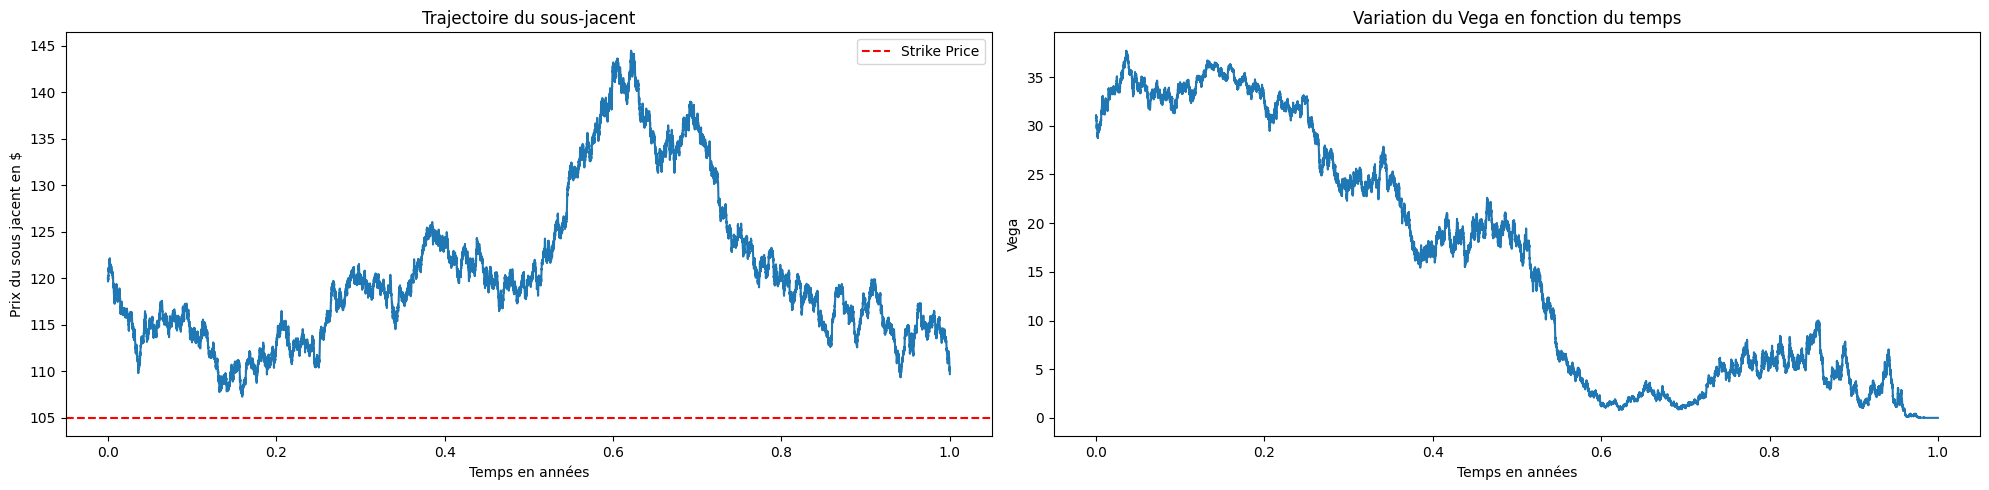

In [58]:
#Paramètres
S0 = 120
sigma = 0.2
r = 0.05
q = 0.02
K = 105
T = 1
N = 25000
option_type = 'call'

S = generer_traj(S0, sigma, r, q, T, N)
vega = Vega_t(S, K, sigma, r, q, T, N, option_type)
t1 = np.linspace(0, T, len(vega))
t2 = np.linspace(0, T, len(S))


plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1)
plt.plot(t2, S)
plt.axhline(y=K, color='r', linestyle='--', label='Strike Price')
plt.xlabel("Temps en années")   
plt.ylabel("Prix du sous jacent en $")  
plt.title("Trajectoire du sous-jacent") 
plt.legend(loc='best')

plt.subplot(1, 2, 2)
plt.plot(t1, vega)
plt.xlabel("Temps en années")
plt.ylabel("Vega")
plt.title("Variation du Vega en fonction du temps")

plt.tight_layout()    
plt.show()  

## Le $\rho$

In [59]:
def Rho_t(S, K, sigma, r, q, T, N, option_type='call'):
    dt = T / N
    rho = np.zeros(N + 1)
    
    for i in range(N + 1):
        tau = T - i * dt
        
        if tau <= 1e-10:
            rho[i] = 0.0
            continue
            
        # Calcul de d1 et d2 
        d1 = (np.log(S[i] / K) + (r - q + (sigma**2) / 2) * tau) / (sigma * np.sqrt(tau))
        d2 = d1 - sigma * np.sqrt(tau)
        
        # Calcul du Rho selon le type d'option
        if option_type == 'call':
            rho[i] = K * tau * np.exp(-r * tau) * norm.cdf(d2)
        elif option_type == 'put':
            rho[i] = -K * tau * np.exp(-r * tau) * norm.cdf(-d2)
            
    return rho

Evolution du $\rho$ en fonction du temps.

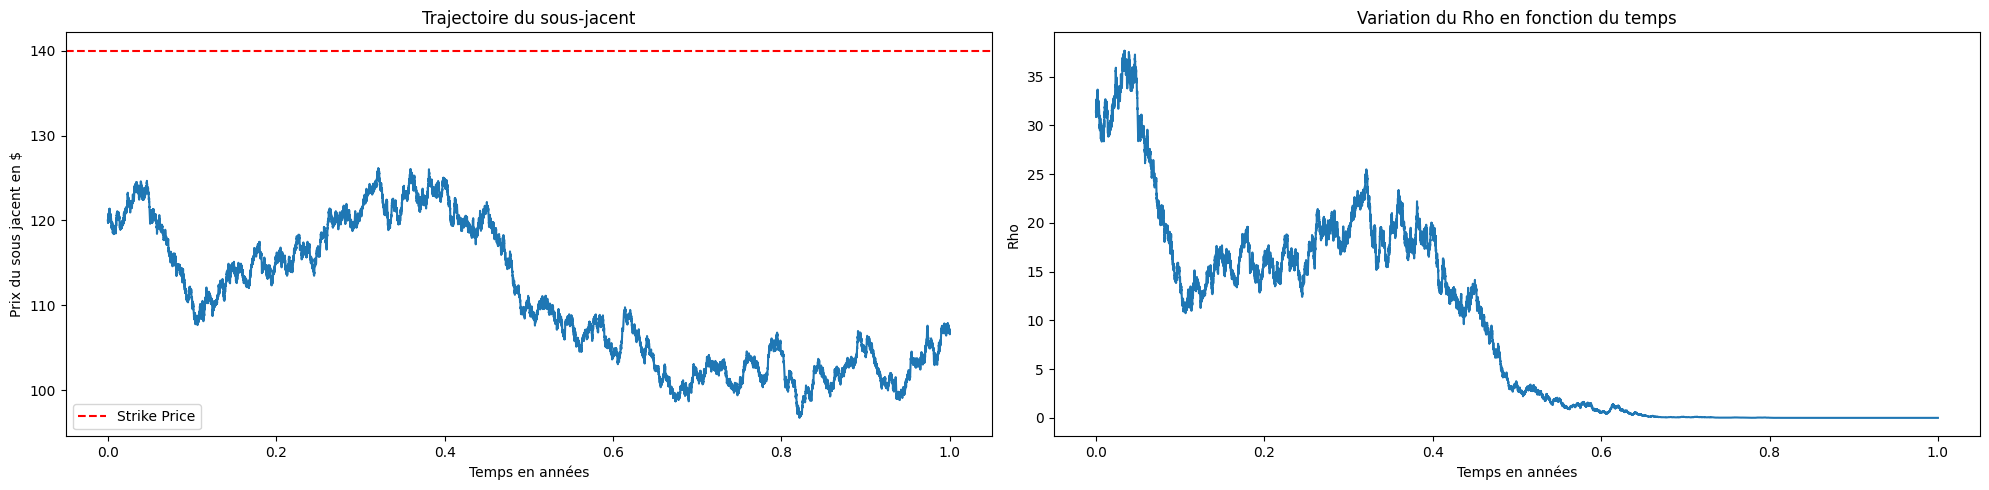

In [60]:
#Paramètres
S0 = 120
sigma = 0.2
r = 0.05
q = 0.02
K = 140
T = 1
N = 25000
option_type = 'call'

S = generer_traj(S0, sigma, r, q, T, N)
rho = Rho_t(S, K, sigma, r, q, T, N, option_type)
t1 = np.linspace(0, T, len(rho))
t2 = np.linspace(0, T, len(S))


plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1)
plt.plot(t2, S)
plt.axhline(y=K, color='r', linestyle='--', label='Strike Price')
plt.xlabel("Temps en années")   
plt.ylabel("Prix du sous jacent en $")  
plt.title("Trajectoire du sous-jacent") 
plt.legend(loc='best')

plt.subplot(1, 2, 2)
plt.plot(t1, rho)
plt.xlabel("Temps en années")
plt.ylabel("Rho")
plt.title("Variation du Rho en fonction du temps")

plt.tight_layout()    
plt.show()  